In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
import warnings
warnings.filterwarnings('ignore')

In [2]:
usecols = [
    'timestamp', 'amount', 'transaction_type', 'merchant_category',
    'location', 'device_used', 'is_fraud', 'time_since_last_transaction',
    'spending_deviation_score', 'velocity_score', 'geo_anomaly_score',
    'payment_channel'
]
data = pd.read_csv(r'../Dataset/financial_fraud_detection_dataset.csv', usecols=usecols)

In [3]:
data.columns

Index(['timestamp', 'amount', 'transaction_type', 'merchant_category',
       'location', 'device_used', 'is_fraud', 'time_since_last_transaction',
       'spending_deviation_score', 'velocity_score', 'geo_anomaly_score',
       'payment_channel'],
      dtype='str')

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000000 entries, 0 to 4999999
Data columns (total 12 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   timestamp                    str    
 1   amount                       float64
 2   transaction_type             str    
 3   merchant_category            str    
 4   location                     str    
 5   device_used                  str    
 6   is_fraud                     bool   
 7   time_since_last_transaction  float64
 8   spending_deviation_score     float64
 9   velocity_score               int64  
 10  geo_anomaly_score            float64
 11  payment_channel              str    
dtypes: bool(1), float64(4), int64(1), str(6)
memory usage: 424.4 MB


In [5]:
data.describe()

,amount,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score
count,5.000000e+06,4.103487e+06,5.000000e+06,5.000000e+06,5.000000e+06
mean,3.589343e+02,1.525799e+00,-3.881160e-04,1.050132e+01,5.000293e-01
std,4.699333e+02,3.576569e+03,1.000807e+00,5.766842e+00,2.886349e-01
min,1.000000e-02,-8.777814e+03,-5.260000e+00,1.000000e+00,0.000000e+00
25%,2.657000e+01,-2.562376e+03,-6.800000e-01,5.000000e+00,2.500000e-01
50%,1.386700e+02,8.442747e-01,0.000000e+00,1.100000e+01,5.000000e-01
75%,5.038900e+02,2.568339e+03,6.700000e-01,1.600000e+01,7.500000e-01
max,3.520570e+03,8.757758e+03,5.020000e+00,2.000000e+01,1.000000e+00


In [6]:
selected_features = [
    'timestamp', 'amount', 'transaction_type', 'merchant_category',
    'location', 'device_used', 'time_since_last_transaction',
    'spending_deviation_score', 'velocity_score', 'geo_anomaly_score',
    'payment_channel'
]
target_col = 'is_fraud'
dropped_features = [
    'transaction_id', 'sender_account', 'receiver_account',
    'ip_address', 'device_hash', 'fraud_type'
]
print('Dropped (IDs / leakage):', dropped_features)
print('Selected features:', selected_features)
df = data[selected_features + [target_col]].copy()
df.shape

Dropped (IDs / leakage): ['transaction_id', 'sender_account', 'receiver_account', 'ip_address', 'device_hash', 'fraud_type']
Selected features: ['timestamp', 'amount', 'transaction_type', 'merchant_category', 'location', 'device_used', 'time_since_last_transaction', 'spending_deviation_score', 'velocity_score', 'geo_anomaly_score', 'payment_channel']


(5000000, 12)

In [7]:
fraud_df = df[df[target_col] == True]
nonfraud_df = df[df[target_col] == False].sample(n=min(100000, len(df[df[target_col] == False])), random_state=42)
df = pd.concat([fraud_df, nonfraud_df], axis=0).sample(frac=1, random_state=42).reset_index(drop=True)
df.shape, df[target_col].value_counts()

((279553, 12),
 is_fraud
 True     179553
 False    100000
 Name: count, dtype: int64)

In [8]:
df.isnull().sum()

timestamp                          0
amount                             0
transaction_type                   0
merchant_category                  0
location                           0
device_used                        0
time_since_last_transaction    18499
spending_deviation_score           0
velocity_score                     0
geo_anomaly_score                  0
payment_channel                    0
is_fraud                           0
dtype: int64

is_fraud
True     179553
False    100000
Name: count, dtype: int64
is_fraud
True     0.642286
False    0.357714
Name: proportion, dtype: float64


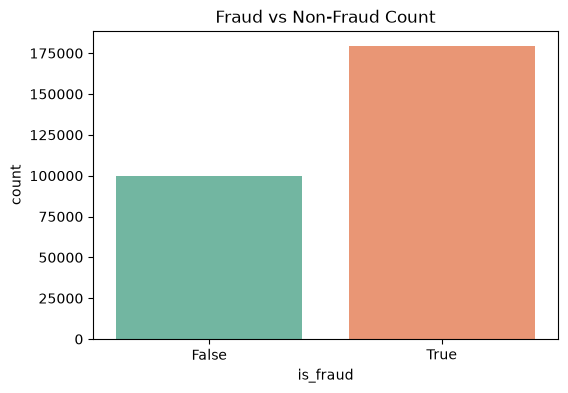

In [9]:
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True))
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df, palette='Set2')
plt.title('Fraud vs Non-Fraud Count')
plt.show()

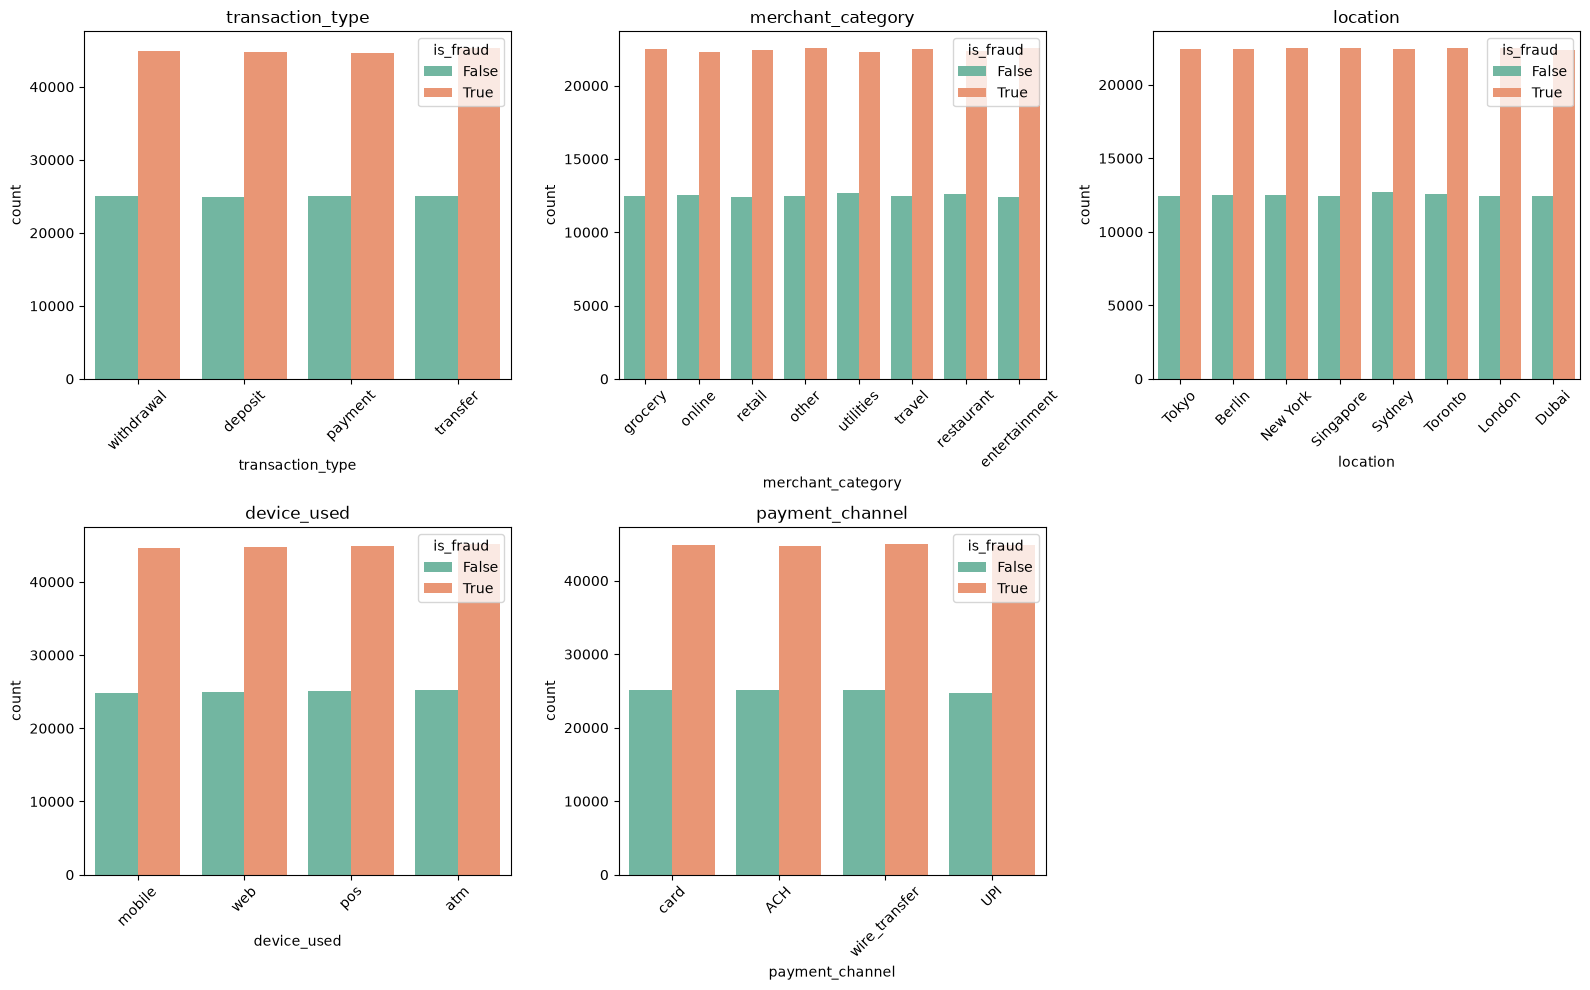

In [10]:
cat_cols = ['transaction_type', 'merchant_category', 'location', 'device_used', 'payment_channel']
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    sns.countplot(x=col, hue=target_col, data=df, ax=axes[i], palette='Set2')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_title(col)
axes[-1].axis('off')
plt.tight_layout()
plt.show()

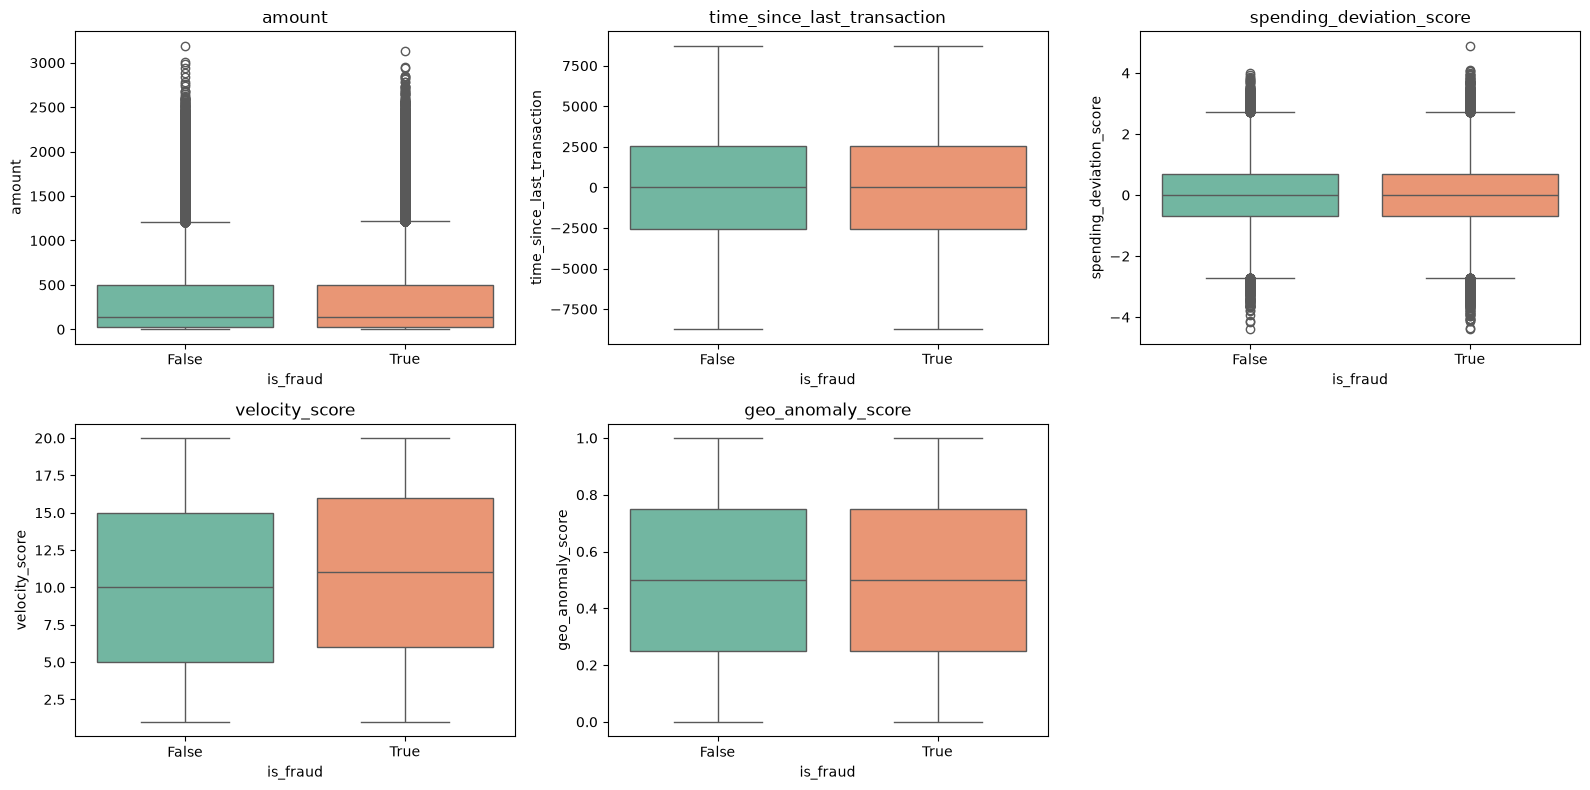

In [11]:
num_cols = ['amount', 'time_since_last_transaction', 'spending_deviation_score', 'velocity_score', 'geo_anomaly_score']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(x=target_col, y=col, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(col)
axes[-1].axis('off')
plt.tight_layout()
plt.show()

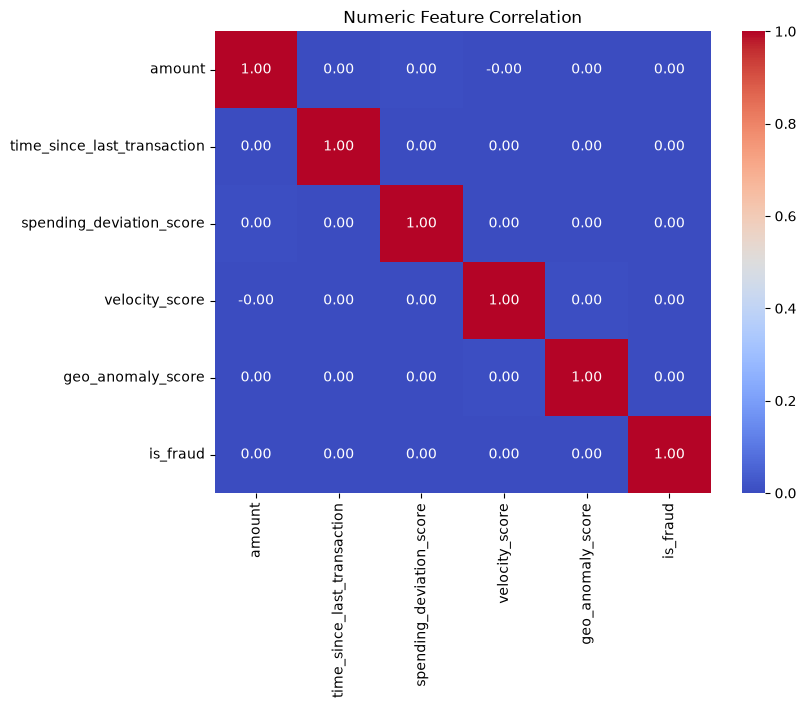

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols + [target_col]].corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numeric Feature Correlation')
plt.show()

In [13]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['month'] = df['timestamp'].dt.month
df = df.drop(columns=['timestamp'])
df['time_since_last_transaction'] = df['time_since_last_transaction'].fillna(df['time_since_last_transaction'].median())
df[target_col] = df[target_col].astype(int)
df.head()

,amount,transaction_type,merchant_category,location,device_used,time_since_last_transaction,spending_deviation_score,velocity_score,geo_anomaly_score,payment_channel,is_fraud,hour,day_of_week,month
0,509.10,withdrawal,grocery,Tokyo,mobile,-14.404135,0.73,8,0.34,card,1,18,1,10
1,613.24,deposit,online,Tokyo,mobile,615.831978,0.44,5,0.21,ACH,0,15,5,8
2,12.12,payment,grocery,Berlin,web,865.532352,-0.59,11,0.75,wire_transfer,1,15,6,9
3,22.58,payment,retail,New York,mobile,-199.556886,0.86,16,0.81,card,1,17,5,2
4,1091.62,deposit,other,Singapore,pos,-3548.873471,-0.38,3,0.71,card,1,12,3,3


In [14]:
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
df.dtypes

amount                         float64
transaction_type                 int64
merchant_category                int64
location                         int64
device_used                      int64
time_since_last_transaction    float64
spending_deviation_score       float64
velocity_score                   int64
geo_anomaly_score              float64
payment_channel                  int64
is_fraud                         int64
hour                             int32
day_of_week                      int32
month                            int32
dtype: object

In [15]:
X = df.drop(columns=[target_col])
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train.shape, X_test.shape, y_train.value_counts().to_dict()

((223642, 13), (55911, 13), {1: 143642, 0: 80000})

In [16]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    if hasattr(model, 'predict_proba'):
        y_prob = model.predict_proba(X_te)[:, 1]
    else:
        y_prob = y_pred
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall': recall_score(y_te, y_pred, zero_division=0),
        'F1-Score': f1_score(y_te, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_te, y_prob)
    }
    print(name)
    print(classification_report(y_te, y_pred, zero_division=0))
    print('Confusion Matrix:\n', confusion_matrix(y_te, y_pred))
    print('-' * 50)
    return metrics, model

In [17]:
results = []
trained_models = {}

m1, trained_models['Logistic Regression'] = evaluate_model(
    'Logistic Regression',
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    X_train_scaled, X_test_scaled, y_train, y_test
)
results.append(m1)

Logistic Regression
              precision    recall  f1-score   support

           0       0.36      0.50      0.42     20000
           1       0.64      0.50      0.56     35911

    accuracy                           0.50     55911
   macro avg       0.50      0.50      0.49     55911
weighted avg       0.54      0.50      0.51     55911

Confusion Matrix:
 [[10082  9918]
 [17895 18016]]
--------------------------------------------------


In [18]:
m2, trained_models['Decision Tree'] = evaluate_model(
    'Decision Tree',
    DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42),
    X_train, X_test, y_train, y_test
)
results.append(m2)

Decision Tree
              precision    recall  f1-score   support

           0       0.77      0.20      0.32     20000
           1       0.69      0.97      0.80     35911

    accuracy                           0.69     55911
   macro avg       0.73      0.59      0.56     55911
weighted avg       0.72      0.69      0.63     55911

Confusion Matrix:
 [[ 4092 15908]
 [ 1229 34682]]
--------------------------------------------------


In [19]:
m3, trained_models['Random Forest'] = evaluate_model(
    'Random Forest',
    RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    X_train, X_test, y_train, y_test
)
results.append(m3)

Random Forest
              precision    recall  f1-score   support

           0       0.92      0.19      0.31     20000
           1       0.69      0.99      0.81     35911

    accuracy                           0.70     55911
   macro avg       0.80      0.59      0.56     55911
weighted avg       0.77      0.70      0.63     55911

Confusion Matrix:
 [[ 3721 16279]
 [  341 35570]]
--------------------------------------------------


In [20]:
m4, trained_models['Gradient Boosting'] = evaluate_model(
    'Gradient Boosting',
    GradientBoostingClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42),
    X_train, X_test, y_train, y_test
)
results.append(m4)

Gradient Boosting
              precision    recall  f1-score   support

           0       0.99      0.18      0.30     20000
           1       0.69      1.00      0.81     35911

    accuracy                           0.71     55911
   macro avg       0.84      0.59      0.56     55911
weighted avg       0.80      0.71      0.63     55911

Confusion Matrix:
 [[ 3554 16446]
 [   25 35886]]
--------------------------------------------------


In [21]:
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.705407,0.685737,0.999304,0.813345,0.589582
1,Random Forest,0.702742,0.686031,0.990504,0.810620,0.587547
2,Decision Tree,0.693495,0.685551,0.965777,0.801887,0.587616
3,Logistic Regression,0.502549,0.644949,0.501685,0.564367,0.501981


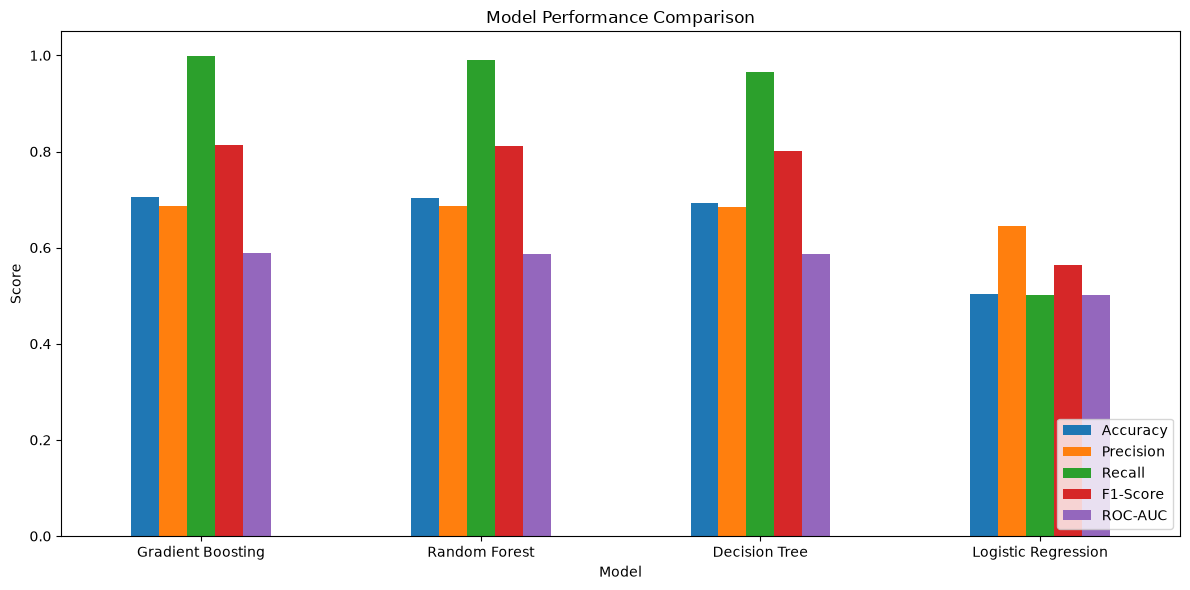

In [22]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
plot_df = results_df.set_index('Model')[metrics_to_plot]
ax = plot_df.plot(kind='bar', figsize=(12, 6), rot=0)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [23]:
best_model_name = results_df.iloc[0]['Model']
best_row = results_df.iloc[0]
print('Best model by F1-Score:', best_model_name)
print(best_row.to_string())
print('\nFull ranking:')
print(results_df.to_string(index=False))
print('\nConclusion:')
print(f'{best_model_name} achieved the highest F1-Score ({best_row["F1-Score"]:.4f}) and is preferred for fraud detection under class imbalance.')
print(f'ROC-AUC of best model: {best_row["ROC-AUC"]:.4f}; Recall: {best_row["Recall"]:.4f}; Precision: {best_row["Precision"]:.4f}.')
print('Tree-based ensembles generally outperform linear models on mixed numeric/categorical fraud signals after encoding.')

Best model by F1-Score: Gradient Boosting
Model        Gradient Boosting
Accuracy              0.705407
Precision             0.685737
Recall                0.999304
F1-Score              0.813345
ROC-AUC               0.589582

Full ranking:
              Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
  Gradient Boosting  0.705407   0.685737 0.999304  0.813345 0.589582
      Random Forest  0.702742   0.686031 0.990504  0.810620 0.587547
      Decision Tree  0.693495   0.685551 0.965777  0.801887 0.587616
Logistic Regression  0.502549   0.644949 0.501685  0.564367 0.501981

Conclusion:
Gradient Boosting achieved the highest F1-Score (0.8133) and is preferred for fraud detection under class imbalance.
ROC-AUC of best model: 0.5896; Recall: 0.9993; Precision: 0.6857.
Tree-based ensembles generally outperform linear models on mixed numeric/categorical fraud signals after encoding.
